# Global Temperature Change Prediction

## Introduction
Our project aims to predict the yearly temperature change of a given city over a given time period, using an <b>ARIMA model</b> for <b>time series forecasting</b>.


### OBJECTIVE : Predicting the Temperature Change of a Given City across a Specified Time Period
<p>To accomplish this, we used data from the <i><a href="https://www.kaggle.com/berkeleyearth/climate-change-earth-surface-temperature-data" target="_blank">Climate Change: Earth Surface Temperature Data</a></i> dataset on Kaggle.</p>

<b>Pre-Processing:</b><br>
<ol>
<li>Converting the 'dt' (date) column to DateTime format</li>
<li>Dropping irrelevant columns and removing rows with NaN values</li>
</ol>
<b>Processing:</b><br>
ARIMA models need the data to be stationary i.e. the data must not exhibit trend and/or seasonality. To identify and remove trend and seasonality, we used the following methods:
<ol>
<li>Plotting the time series to visually check for trend and seasonality</li>
<li>Checking if the histogram of the data fits a Gaussian Curve, and then splitting data into two parts, calculating means and variances and seeing if they vary</li>
<li>Calculating the Augmented Dickey-Fuller Test statistic and using the p-value to determine stationarity</li>
</ol>
If the data was not stationary, we performed <b>differencing</b> to make it stationary.
<br><br>
<b>Fitting the ARIMA model:</b><br>
We performed a grid-search to estimate the best p, q values for the model, for the given data.<br>
We then fit the ARIMA model using the calculated p, q values.
<br><br>
<b>Evaluation:</b><br>
We calculated the <b>Mean Squared Error (MSE)</b> to estimate the performance of the model.

In [1]:
!pip install --user chart-studio


In [2]:
!pip install chart-studio


In [3]:
import chart_studio.plotly as py
from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot
import plotly.graph_objs as go

init_notebook_mode(connected=True)


In [4]:
# import packages
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima_model import ARIMA, ARMAResults
from sklearn.metrics import mean_squared_error
import ipywidgets as widgets

# hide warnings
import warnings
warnings.simplefilter("ignore")

# checking if plotly is installed; install otherwise
!pip install chart-studio

try:
    import chart_studio.plotly as py
except:
    !pip install --user chart-studio
    import chart_studio.plotly as py

from plotly.offline import download_plotlyjs, init_notebook_mode, plot, iplot
import plotly.graph_objs as go
init_notebook_mode(connected=True)


# checking if seaborn is installed; install otherwise
try:
    import seaborn as sns
except:
    ! pip install --user seaborn
    import seaborn as sns

In [5]:
# read the csv file into a DataFrame
df = pd.read_csv("C:/Users/hp/Downloads/GlobalLandTemperaturesByCity.csv/GlobalLandTemperaturesByCity.csv")

df

,dt,AverageTemperature,AverageTemperatureUncertainty,City,Country,Latitude,Longitude
0,1743-11-01,6.068,1.737,Århus,Denmark,57.05N,10.33E
1,1743-12-01,NaN,NaN,Århus,Denmark,57.05N,10.33E
2,1744-01-01,NaN,NaN,Århus,Denmark,57.05N,10.33E
3,1744-02-01,NaN,NaN,Århus,Denmark,57.05N,10.33E
4,1744-03-01,NaN,NaN,Århus,Denmark,57.05N,10.33E
...,...,...,...,...,...,...,...
8599207,2013-05-01,11.464,0.236,Zwolle,Netherlands,52.24N,5.26E
8599208,2013-06-01,15.043,0.261,Zwolle,Netherlands,52.24N,5.26E
8599209,2013-07-01,18.775,0.193,Zwolle,Netherlands,52.24N,5.26E
8599210,2013-08-01,18.025,0.298,Zwolle,Netherlands,52.24N,5.26E


In [6]:
# convert first column to DateTime format
df['dt'] = pd.to_datetime(df['dt'])

# set first column (dt) as the index column
df.index = df['dt']
del df['dt']

# dropping unnecessary columns and combining City and Country
df = df.drop(columns=["AverageTemperatureUncertainty", "Latitude", "Longitude"])
df["City"] = df["City"] + ", " + df["Country"]
df = df.drop(columns="Country")

# removing all rows with NaN values
df = df.dropna()

# get list of all cities in dataset
cities = set(df.City)


In [7]:
# check stationarity in time series data of a given city

def check_stationarity(city_df):
    # method1: plot the time series to check for trend and seasonality
    city_df.plot(figsize=(10, 10))
    
    # method 2: check if histogram fits a Gaussian Curve, then split data into two parts, calculate means and variances and see if they vary
    city_df.hist(figsize=(10, 10))
    plt.show()
    
    X = city_df["AverageTemperature"].values
    split = int(len(X) / 2)
    X1, X2 = X[0:split], X[split:]
    mean1, mean2 = X1.mean(), X2.mean()
    var1, var2 = X1.var(), X2.var()
    print('mean1=%f, mean2=%f' % (mean1, mean2))
    print('variance1=%f, variance2=%f' % (var1, var2))
    
    # if corresponding means and variances differ slightly (by less than 10), we consider that the time series might be stationary
    if (abs(mean1-mean2) <= 10 and abs(var1-var2) <= 10):
        print("Time Series may be Stationary, since means and variances vary only slightly.\n")
    else:
        print("Time Series may NOT be Stationary, since means and variances vary significantly.\n")
        
    # method3: statistical test (Augmented Dickey-Fuller statistic)
    print("Performing Augmented Dickey-Fuller Test to confirm stationarity...")
    
    result = adfuller(X)
    print('ADF Statistic: %f' % result[0])
    print('p-value: %f' % result[1])
    
    p = result[1]
    if (p > 0.05):
        print("Time Series is NOT Stationary, since p-value > 0.05")
        city_df = city_df.diff()  # differencing to make data stationary
        return False
    else:
        print("Time Series is Stationary, since p-value <= 0.05")
        return True

In [8]:
print(sorted(df['City'].unique()))
city = 'New York, United States'  # Or any city from the printed list
df_city = df[df['City'] == city].drop(columns='City')



['A Coruña, Spain', 'Aachen, Germany', 'Aalborg, Denmark', 'Aba, Nigeria', 'Abadan, Iran', 'Abakaliki, Nigeria', 'Abakan, Russia', 'Abbotsford, Canada', "Abengourou, Côte D'Ivoire", 'Abeokuta, Nigeria', 'Aberdeen, United Kingdom', 'Abha, Saudi Arabia', "Abidjan, Côte D'Ivoire", 'Abiko, Japan', 'Abilene, United States', 'Abohar, India', 'Abomey Calavi, Benin', 'Abu Dhabi, United Arab Emirates', 'Abuja, Nigeria', 'Acapulco, Mexico', 'Acarigua, Venezuela', 'Accra, Ghana', 'Achalpur, India', 'Acheng, China', 'Achinsk, Russia', 'Acuña, Mexico', 'Adana, Turkey', 'Addis Abeba, Ethiopia', 'Adelaide, Australia', 'Aden, Yemen', 'Adilabad, India', 'Adiwerna, Indonesia', 'Adoni, India', 'Afyonkarahisar, Turkey', 'Agadir, Morocco', 'Agartala, India', "Agboville, Côte D'Ivoire", 'Ageo, Japan', 'Agra, India', 'Aguascalientes, Mexico', 'Ahmadabad, India', 'Ahmadnagar, India', 'Ahmadpur East, Pakistan', 'Ahvaz, Iran', 'Aix En Provence, France', 'Aizawl, India', 'Ajdabiya, Libya', 'Ajmer, India', 'Akash

Stationarity Check for             AverageTemperature
dt                            
1743-11-01               3.264
1744-04-01               9.788
1744-05-01              15.708
1744-06-01              21.210
1744-07-01              22.207
...                        ...
2013-05-01              15.544
2013-06-01              20.892
2013-07-01              24.722
2013-08-01              21.001
2013-09-01              17.408

[3119 rows x 1 columns]


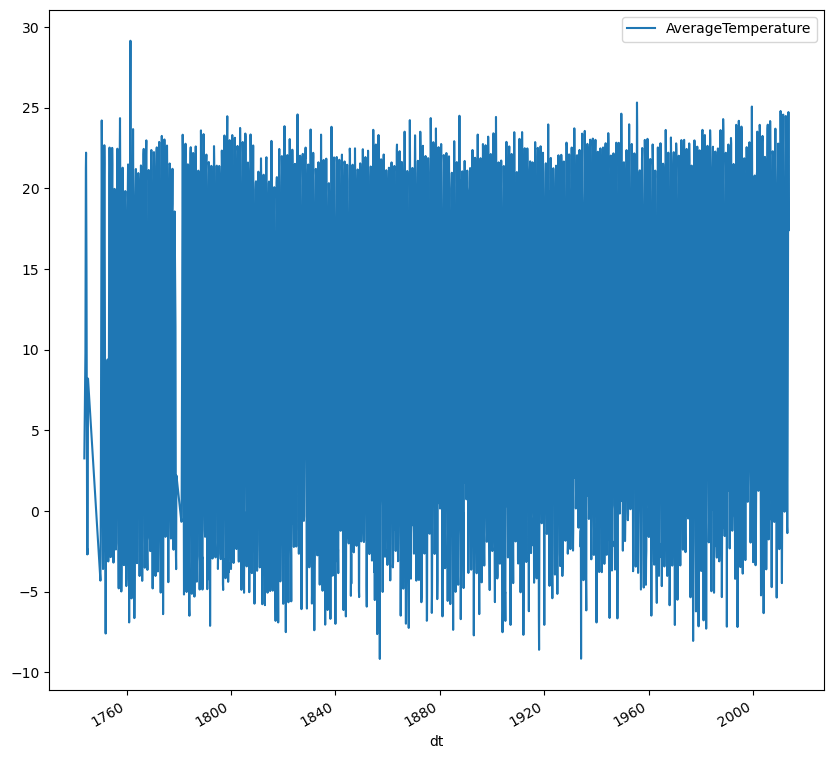

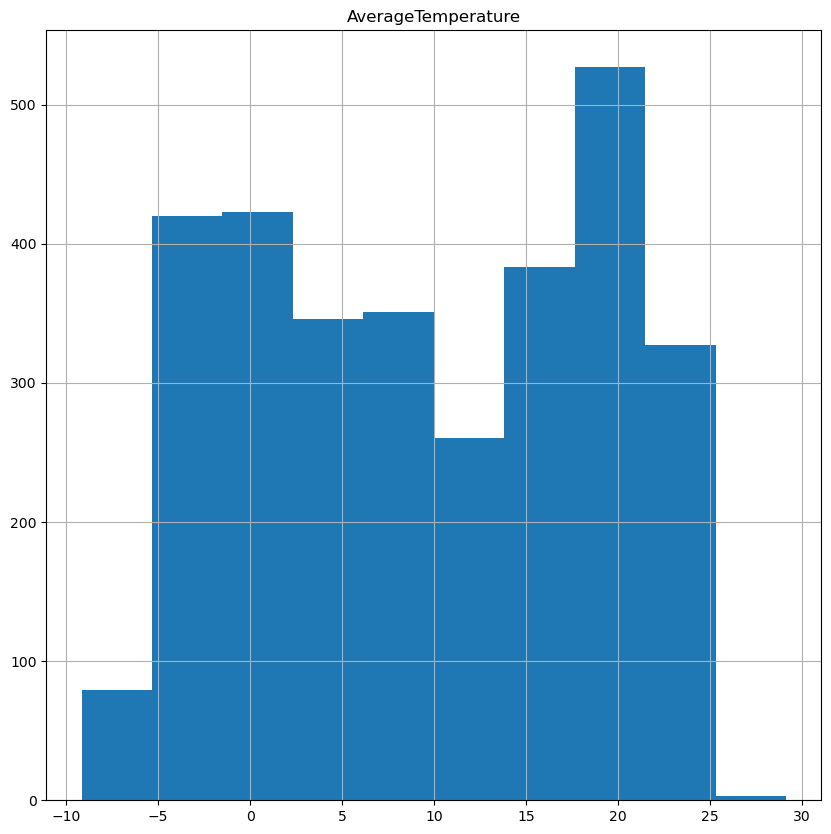

mean1=9.117772, mean2=9.928560
variance1=86.640935, variance2=84.126356
Time Series may be Stationary, since means and variances vary only slightly.

Performing Augmented Dickey-Fuller Test to confirm stationarity...
ADF Statistic: -5.157735
p-value: 0.000011
Time Series is Stationary, since p-value <= 0.05


In [11]:
print ("Stationarity Check for %s" % df_city)
is_stationary = check_stationarity(df_city)

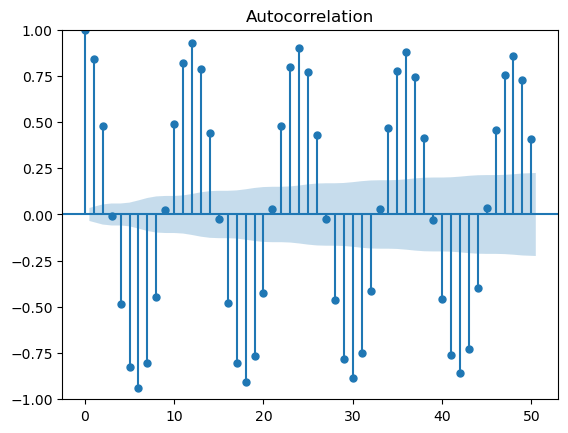

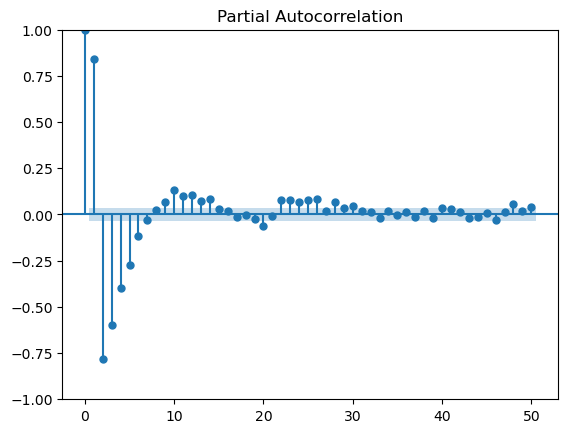

In [13]:
# ACF and PACF plots

plot_acf(df_city,lags = 50)
plot_pacf(df_city,lags = 50)
plt.show()

# setting d value for ARIMA model
if (is_stationary==True):
    d = 0
else:
    d = 1

,AverageTemperature
dt,
1743-11-01,False
1744-04-01,False
1744-05-01,False
1744-06-01,False
1744-07-01,False
...,...
2013-05-01,False
2013-06-01,False
2013-07-01,False


In [19]:
# Although we can determine p, q values manually by looking at the ACF and PACF plots for a given city, we must automate the process
# To automate the process, we must perform a grid search over different values of p and q and choose the ARIMA model for which the AIC and BIC values are minimum
from statsmodels.tsa.arima.model import ARIMA
import numpy as np

# Define the differencing order (d), make sure it's set correctly
d = 1  # or choose based on your data

p_range = q_range = list(range(0, 3))  # taking values from 0 to 2

aic_values = []
bic_values = []
pq_values = []

for p in p_range:
    for q in q_range:
        try:
            model = ARIMA(df_city, order=(p, d, q))
            results = model.fit()
            aic_values.append(results.aic)
            bic_values.append(results.bic)
            pq_values.append((p, q))
        except Exception as e:
            print(f"Error for p={p}, q={q}: {e}")
            pass

# Check if aic_values is not empty before proceeding
if aic_values:
    best_pq = pq_values[aic_values.index(min(aic_values))]  # (p,q) corresponding to lowest AIC score
    print("(p,q) corresponding to lowest AIC score: ", best_pq)
else:
    print("No valid ARIMA models were fitted.")



(p,q) corresponding to lowest AIC score:  (2, 2)


In [22]:
# fitting an ARIMA model with chosen p, d, q values and calculating the mean squared error
from sklearn.metrics import mean_absolute_error

arima_model = ARIMA(df_city, order=(best_pq[0], 0, best_pq[1])).fit()
predictions = arima_model.predict(start=0, end=len(df_city)-1)

mse = mean_squared_error(list(df_city.AverageTemperature), list(predictions))
print("Mean Squared Error:", mse)

mae = mean_absolute_error(list(df_city.AverageTemperature), list(predictions))
print("Mean Absolute Error:", mae)

Mean Squared Error: 4.678029980483537
Mean Absolute Error: 1.57799625221214


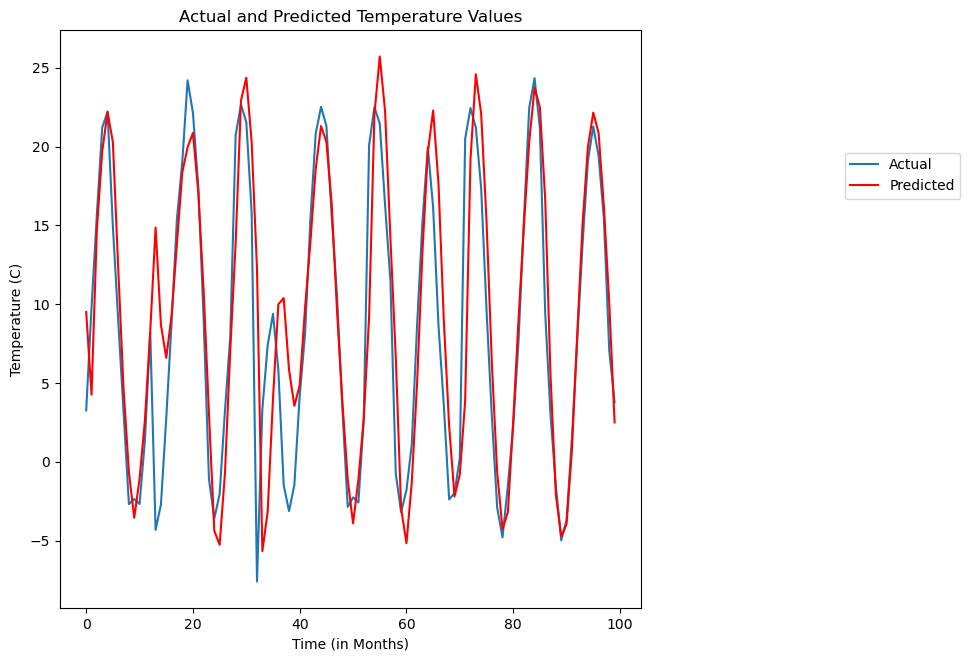

In [23]:
# comparing first 100 predictions with actual values

plt.figure(figsize=(7.5,7.5))
plt.plot(list(df_city.AverageTemperature)[:100], label="Actual")
plt.plot(list(predictions)[:100], 'r', label="Predicted")

plt.xlabel("Time (in Months)")
plt.ylabel("Temperature (C)")
plt.title("Actual and Predicted Temperature Values")

plt.legend(loc='upper center', bbox_to_anchor=(1.45, 0.8))
plt.show()

In [27]:
import ipywidgets as widgets

# Manual input for number of years
years_input_field = widgets.IntText(
    value=10,  # Default value
    description='No. of Years:',
    min=1,  # Minimum value (at least 1 year)
    max=200,  # Maximum value (at most 200 years)
    step=1,  # Step size
    disabled=False
)

years_input_field

number_of_years = years_input_field.value


In [33]:
# Ensure forecast() returns predictions as expected
forecast_results = arima_model.forecast(steps=number_of_steps)

# Inspect the structure of the forecast results
print(type(forecast_results))  # Check the type
print(forecast_results)        # Check the content

# If forecast_results is a Pandas Series:
if isinstance(forecast_results, pd.Series):
    out_of_sample_forecast = forecast_results[remaining_months:]

# If forecast_results is a tuple (first element is the forecast values):
elif isinstance(forecast_results, tuple):
    out_of_sample_forecast = forecast_results[0][remaining_months:]

# Print or inspect the forecasted values
print(out_of_sample_forecast)


<class 'pandas.core.series.Series'>
3119    10.256752
3120     3.392472
3121    -1.752292
3122    -3.807626
3123    -2.250685
          ...    
3237    14.502761
3238    11.068912
3239     7.249552
3240     4.078581
3241     2.404532
Name: predicted_mean, Length: 123, dtype: float64
3122    -3.807626
3123    -2.250685
3124     2.461919
3125     9.027223
3126    15.655893
          ...    
3237    14.502761
3238    11.068912
3239     7.249552
3240     4.078581
3241     2.404532
Name: predicted_mean, Length: 120, dtype: float64


In [34]:
# displaying forecasted values for the nth year

months = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
i = 0
for x in out_of_sample_forecast[-12:]:  # last year
    print(months[i]+": ", x, 'C')
    i += 1

January:  2.145732524795662 C
February:  4.258318881183205 C
March:  7.7656112137594615 C
April:  11.707598624869924 C
May:  15.0168097822486 C
June:  16.807274755456508 C
July:  16.611601388055696 C
August:  14.502760771726454 C
September:  11.068912255016308 C
October:  7.2495519092981 C
November:  4.078581499637821 C
December:  2.4045322652680436 C


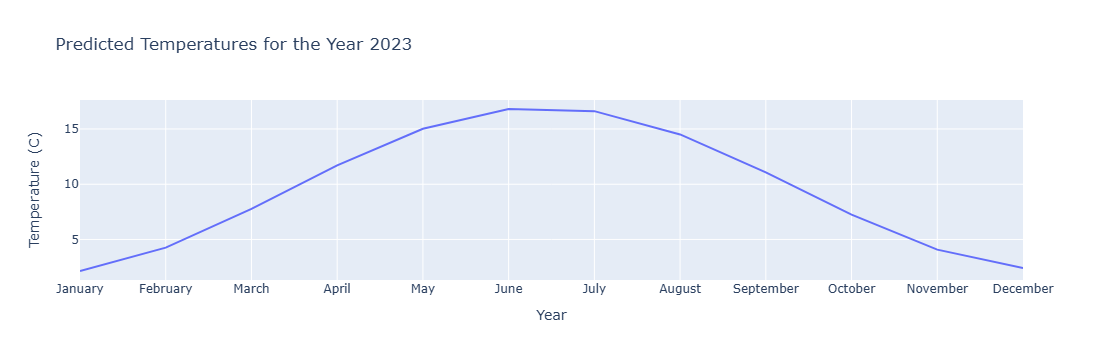

In [35]:
# plotting the predicted values for the nth year

trace = go.Scatter(
    x = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"],
    y = out_of_sample_forecast[-12:],
    mode = 'lines',
    name = 'Average Temperature'
)

layout = go.Layout(
    title='Predicted Temperatures for the Year %d' % (2013+num_years),
    xaxis=dict(
        title='Year',
    ),
    yaxis=dict(
        title='Temperature (C)',
    )
)
data = [trace]

fig = go.Figure(data=data, layout=layout)
iplot(fig)

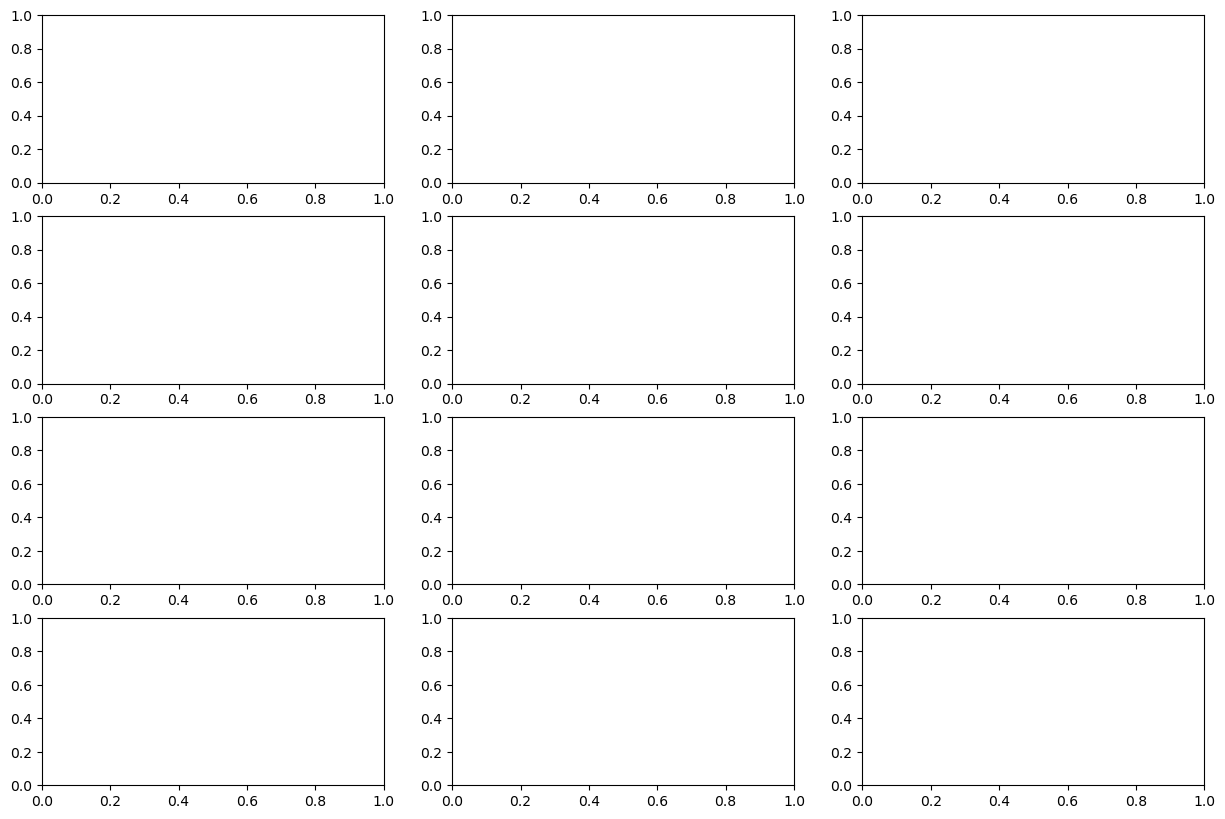

In [40]:
fig, ax = plt.subplots(nrows=4, ncols=3, figsize=(15, 10))
monthly_change = {}

for month in range(12):
    temp = month
    for year in range(num_years):
        if month not in monthly_change:
            monthly_change[month] = [out_of_sample_forecast.iloc[temp]]
        else:
            monthly_change[month].append(out_of_sample_forecast.iloc[temp])
        temp += 12


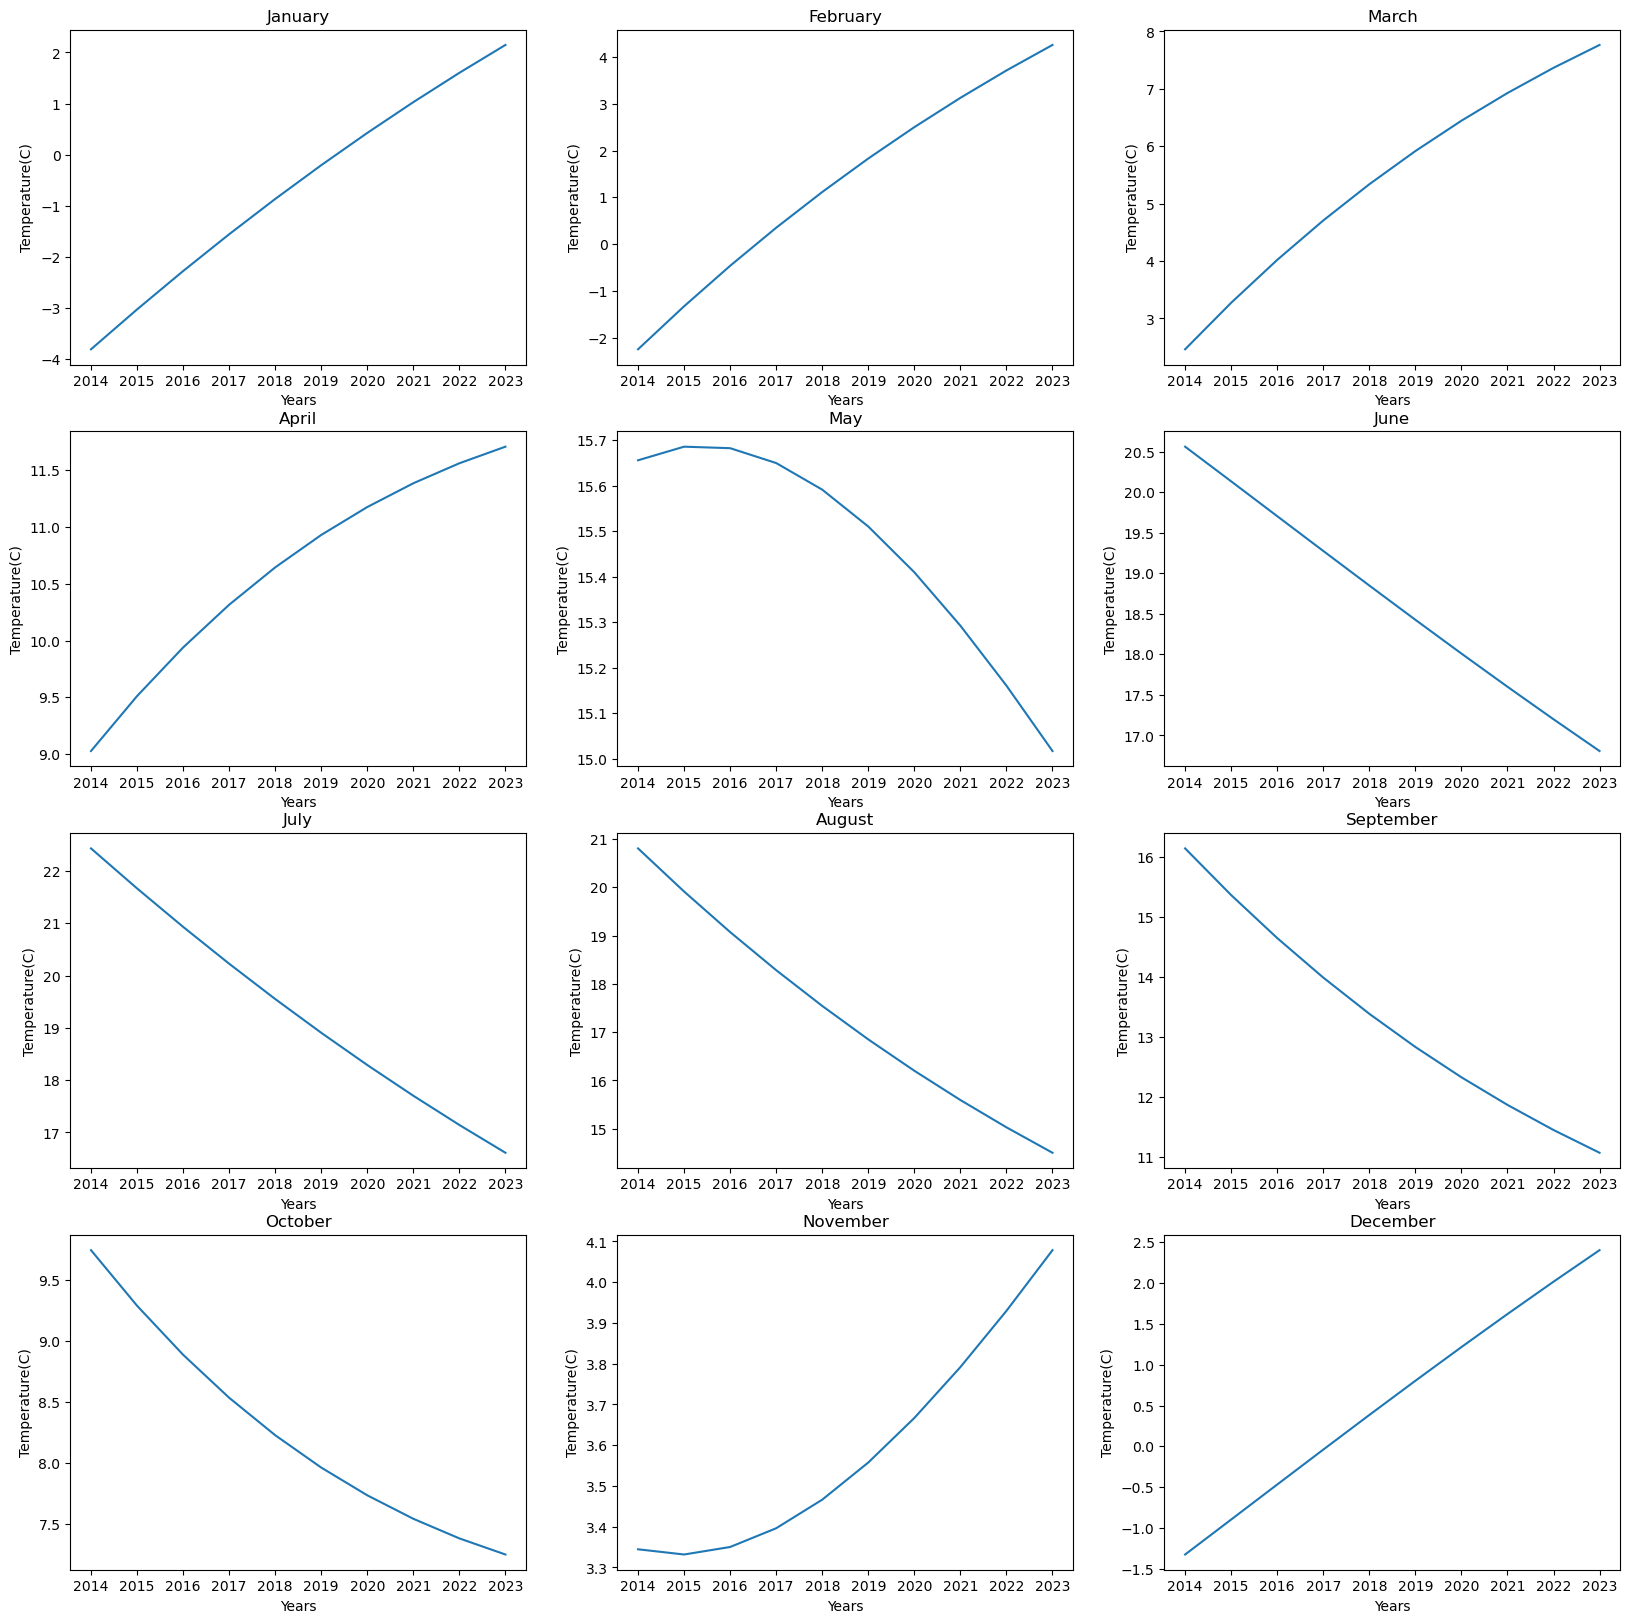

In [41]:
plt.figure(figsize=(20,20))
for pos in range(0,12):
    plt.subplot(4,3,pos+1)
    plt.plot(monthly_change[pos])
    plt.xticks(np.array(range(num_years)), [i for i in range(2014,2014+num_years)])
    plt.title(months[pos])
    plt.xlabel('Years')
    plt.ylabel('Temperature(C)')

plt.show()

When we forecasted the future temperature values for New York, we could infer from the above plots that the summers seem to be getting cooler and the winters seem to be getting warmer over the next decade.<br>

